# 05 · Avaliação automática da qualidade da imagem

**Ementa 05** · Antes de qualquer inferência, o retinógrafo precisa decidir: **esta captura serve?** Um modelo de IA sempre devolve *alguma* resposta — inclusive para uma imagem borrada ou escura, quando a resposta não vale nada.
O controle de qualidade é o "porteiro" do pipeline e ainda alimenta o operador com instruções (*"reduza a luz", "refaça o foco"*).

Meta do edital (Tabela 3): **≥ 80 % das capturas com qualidade adequada à leitura**. Para *medir* isso, precisamos de um avaliador automático — e de uma forma honesta de validá-lo.

Neste notebook você vai:
1. calcular métricas de foco, iluminação, contraste, ruído e enquadramento em 115 imagens reais;
2. ver como **degradações sintéticas** (com intensidade conhecida) movem cada métrica;
3. **calibrar limiares** e medir taxa de detecção × falsos alarmes;
4. comparar regras simples com um classificador aprendido;
5. entender por que os limiares são **específicos da câmera** e como calibrá-los no dispositivo;
6. medir a **latência** e gerar mensagens para o operador.

> **Sem verdade de "qualidade".** Nenhuma base traz rótulo confiável de qualidade. Por isso validamos de dois jeitos complementares: **(a)** degradações sintéticas — sabemos exatamente o defeito e a intensidade; **(b)** inspeção visual das imagens reais reprovadas.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
import itertools, time
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from retina_pdi import qualidade as Q, degradacoes, metricas as M

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


## 1. As métricas (e o que cada uma mede)

Todas são calculadas na versão **padronizada** da imagem (recorte do FOV, quadrada, 512×512) e só dentro do FOV, para não depender da resolução da câmera nem da moldura preta (veja o notebook 01).

| Critério (Módulo 1) | Métrica | O que mede |
|---|---|---|
| Foco | `nitidez_rel` | variância do Laplaciano ÷ variância do canal verde — alta frequência *relativa ao contraste* |
| Foco | `tenengrad` | energia do gradiente (Sobel) |
| Ruído | `ruido` | σ estimado pelo método de Immerkaer |
| Iluminação | `brilho`, `p_saturado`, `p_escuro` | luminância média; fração de pixels ≥ 250 e < 25 |
| Iluminação | `desigualdade` | variação relativa do "fundo" de iluminação (gaussiano largo) |
| Contraste | `contraste`, `entropia` | desvio-padrão e entropia do canal verde |
| Centralização | `desvio_centro`, `cobertura_fov`, `preenchimento_bbox`, `toca_borda` | posição/forma do FOV no quadro |

In [2]:
man = dados.carregar_manifesto()
linhas = []
for _, r in man.iterrows():
    im = dados.reduzir(dados.carregar_rgb(r.arquivo), 1024)          # 1024 px basta: a padronização reduz para 512
    linhas.append(dict(id=r.id, fonte=r.fonte, condicao=r.condicao, **Q.metricas_qualidade(im)))
real = pd.DataFrame(linhas)
print(f"{len(real)} imagens medidas")
real.groupby("fonte")[["nitidez_rel", "ruido", "brilho", "p_saturado", "p_escuro", "desigualdade", "contraste", "desvio_centro"]].median().round(3)

115 imagens medidas


,nitidez_rel,ruido,brilho,p_saturado,p_escuro,desigualdade,contraste,desvio_centro
fonte,,,,,,,,
HRF,0.210,0.689,94.987,0.005,0.000,0.114,16.190,0.005
ODIR,0.089,0.777,111.311,0.003,0.001,0.153,24.030,0.001
RFMiD,0.183,0.918,86.771,0.014,0.001,0.140,18.376,0.003


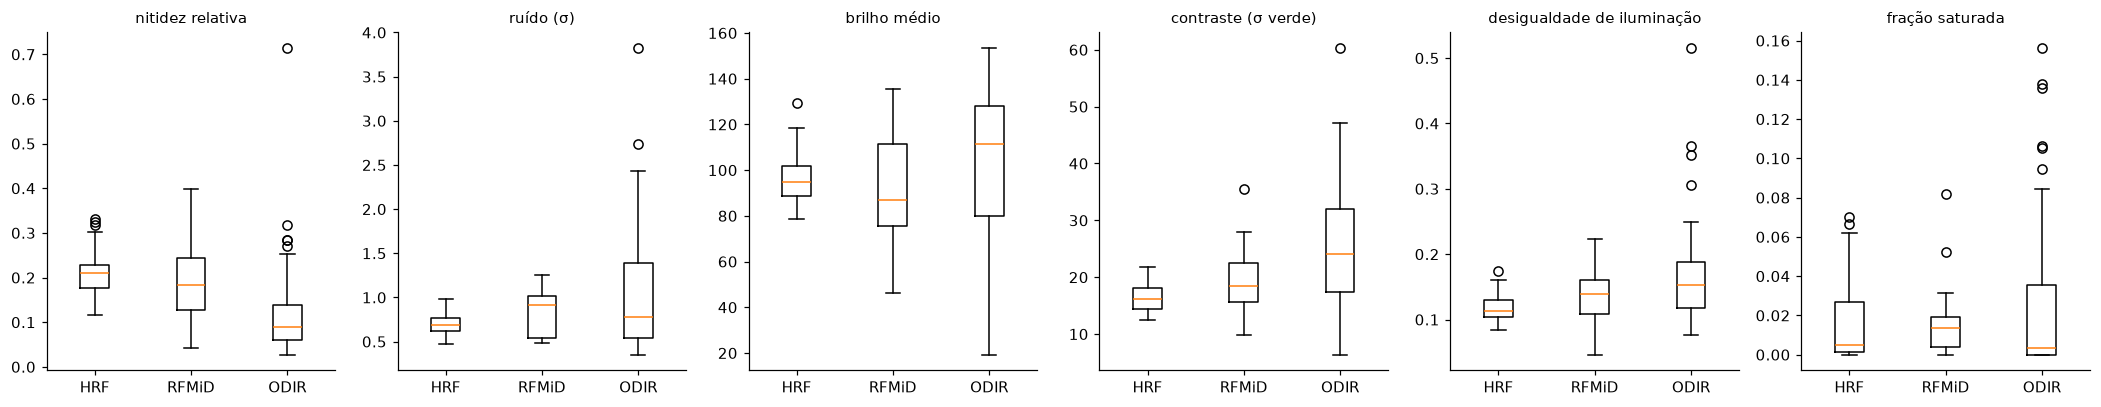

In [3]:
cols = [("nitidez_rel", "nitidez relativa"), ("ruido", "ruído (σ)"), ("brilho", "brilho médio"), ("contraste", "contraste (σ verde)"), ("desigualdade", "desigualdade de iluminação"), ("p_saturado", "fração saturada")]
fig, axs = plt.subplots(1, len(cols), figsize=(3.2 * len(cols), 3.8))
for ax, (c, t_) in zip(axs, cols):
    fontes = ["HRF", "RFMiD", "ODIR"]
    ax.boxplot([real[real.fonte == f][c] for f in fontes], showfliers=True); ax.set_xticklabels(fontes); ax.set_title(t_, fontsize=10)
fig.tight_layout(); V.salvar_figura(fig, "05_metricas_por_fonte"); plt.show()

Cada câmera tem sua "assinatura": a nitidez relativa do HRF é bem maior que a do ODIR (imagens de 512 px, já reamostradas), o brilho e o contraste também diferem.
**Um limiar único vale para uma câmera, não para todas** — voltaremos a isso na seção 6.

## 2. Degradações sintéticas: o que cada defeito faz com as métricas

Partimos de 22 imagens reais (2 por combinação fonte × condição) e aplicamos seis defeitos em seis níveis (0,17 … 1,0). A linha é a **mediana** entre as imagens e a faixa vai do mínimo ao máximo.
As linhas tracejadas são os limiares padrão de `retina_pdi.qualidade.LIMIARES_PADRAO`. *(Leva ~ 1–2 minutos.)*

In [4]:
base = man.groupby(["fonte", "condicao"]).head(2).reset_index(drop=True)
niveis = [0.17, 0.33, 0.5, 0.66, 0.83, 1.0]
linhas = []
for _, r in base.iterrows():
    im = dados.reduzir(dados.carregar_rgb(r.arquivo), 1024)
    orig = real[real.id == r.id].iloc[0].drop(["id", "fonte", "condicao"]).to_dict()
    linhas.append(dict(id=r.id, fonte=r.fonte, tipo="original", nivel=0.0, **orig))
    for tipo, nivel in itertools.product(degradacoes.TIPOS, niveis):
        linhas.append(dict(id=r.id, fonte=r.fonte, tipo=tipo, nivel=nivel, **Q.metricas_qualidade(degradacoes.aplicar(im, tipo, nivel, seed=int(100 * nivel)))))
degr = pd.DataFrame(linhas)
print(len(base), "imagens-base ×", len(degradacoes.TIPOS), "defeitos ×", len(niveis), "níveis =", (degr.tipo != "original").sum(), "imagens degradadas")

22 imagens-base × 6 defeitos × 6 níveis = 792 imagens degradadas


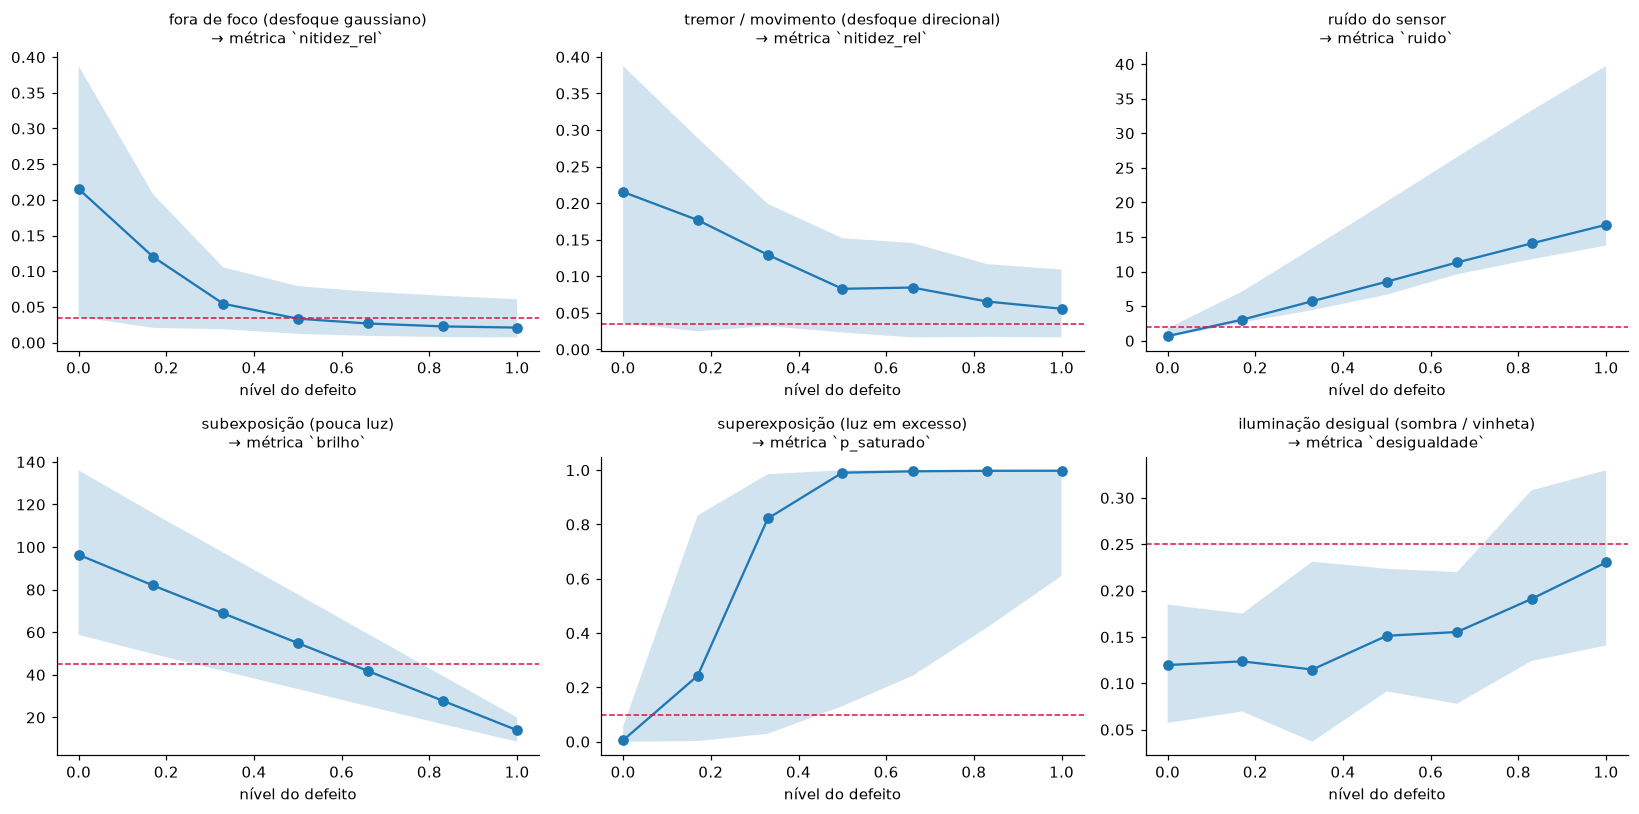

In [5]:
L = Q.LIMIARES_PADRAO
paineis = [("desfoque", "nitidez_rel", L.nitidez_rel_min), ("movimento", "nitidez_rel", L.nitidez_rel_min), ("ruido", "ruido", L.ruido_max),
           ("escuro", "brilho", L.brilho_min), ("claro", "p_saturado", L.p_saturado_max), ("desigual", "desigualdade", L.desigualdade_max)]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (tipo, met, lim) in zip(axs.ravel(), paineis):
    sub = pd.concat([degr[degr.tipo == "original"].assign(tipo=tipo), degr[degr.tipo == tipo]])
    g = sub.groupby("nivel")[met]
    ax.fill_between(g.min().index, g.min(), g.max(), alpha=0.2); ax.plot(g.median().index, g.median(), "o-")
    ax.axhline(lim, color="crimson", ls="--", lw=1); ax.set_title(f"{degradacoes.DESCRICAO[tipo]}\n→ métrica `{met}`", fontsize=10); ax.set_xlabel("nível do defeito")
fig.tight_layout(); V.salvar_figura(fig, "05_metricas_vs_degradacao"); plt.show()

Observações: **ruído**, **subexposição** e **superexposição** movem suas métricas de forma clara e monotônica; **desfoque** também, mas a faixa dos originais já é larga (câmeras diferentes); **movimento** e **sombra suave** deslocam pouco a métrica correspondente.
Um defeito **direcional** (movimento) borra só numa direção, e a variância do Laplaciano mede a média das direções — por isso o exercício 3.

## 3. Calibração dos limiares

Para cada defeito, quão bem a métrica *sozinha* separa "degradada (nível ≥ 0,66)" de "original"? Medimos a **AUC** (1 = separa perfeitamente; 0,5 = acaso) e comparamos o limiar padrão com o percentil das 115 imagens originais.
*Aviso:* os originais **não são todos bons** (o ODIR tem capturas ruins de verdade), então percentis extremos são uma escolha **conservadora**.

In [6]:
regras = [("desfoque", "nitidez_rel", "menor = pior", L.nitidez_rel_min, 5), ("movimento", "nitidez_rel", "menor = pior", L.nitidez_rel_min, 5),
          ("ruido", "ruido", "maior = pior", L.ruido_max, 95), ("escuro", "brilho", "menor = pior", L.brilho_min, 5),
          ("claro", "p_saturado", "maior = pior", L.p_saturado_max, 95), ("desigual", "desigualdade", "maior = pior", L.desigualdade_max, 95)]
linhas = []
for tipo, met, sentido, lim, pct in regras:
    ruim = degr[(degr.tipo == tipo) & (degr.nivel >= 0.66)][met]; bom = real[met]
    escore = np.r_[bom, ruim] * (-1 if "menor" in sentido else 1)
    rotulo = np.r_[np.zeros(len(bom)), np.ones(len(ruim))]
    linhas.append(dict(defeito=tipo, métrica=met, sentido=sentido, AUC=roc_auc_score(rotulo, escore), limiar_padrão=lim, **{"percentil dos originais": np.percentile(bom, pct)}, percentil=f"p{pct}"))
pd.DataFrame(linhas).round(3)

,defeito,métrica,sentido,AUC,limiar_padrão,percentil dos originais,percentil
0,desfoque,nitidez_rel,menor = pior,0.975,0.035,0.040,p5
1,movimento,nitidez_rel,menor = pior,0.861,0.035,0.040,p5
2,ruido,ruido,maior = pior,1.000,2.000,1.604,p95
3,escuro,brilho,menor = pior,0.987,45.000,56.431,p5
4,claro,p_saturado,maior = pior,1.000,0.100,0.088,p95
5,desigual,desigualdade,maior = pior,0.808,0.250,0.242,p95


Leia assim: um AUC alto com o limiar padrão **próximo do percentil (p5 ou p95) dos originais** significa que reprovamos ≈ 5 % das imagens "normais" para pegar a maioria dos defeitos fortes — o compromisso entre **falsos alarmes** (recapturar sem necessidade) e **defeitos não detectados** (inferir sobre uma imagem ruim).
Em triagem, o custo de um falso alarme é baixo (uma nova captura); o de um defeito não detectado pode ser alto — por isso limiares conservadores.

## 4. Regras em ação

### 4.1 Nas 115 imagens reais
Aplicamos `julgar_metricas` com os limiares padrão e vemos a taxa de aprovação por fonte (meta do edital: ≥ 80 %):

In [7]:
def julgar(df, lim=Q.LIMIARES_PADRAO):
    res = [Q.julgar_metricas(r.to_dict(), lim) for _, r in df.iterrows()]
    return pd.Series([x.adequada for x in res], index=df.index), pd.Series(["; ".join(x.motivos) for x in res], index=df.index)

real["adequada"], real["motivos"] = julgar(real)
taxa = real.groupby("fonte").adequada.mean().mul(100).round(1)
print(f"aprovação global: {100*real.adequada.mean():.1f}%   (meta do edital ≥ 80% — aqui medida em bases públicas, não no dispositivo)")
print(taxa.to_string())
real[~real.adequada][["id", "motivos"]].reset_index(drop=True)

aprovação global: 89.6%   (meta do edital ≥ 80% — aqui medida em bases públicas, não no dispositivo)
fonte
HRF      100.0
ODIR      73.8
RFMiD     96.4


,id,motivos
0,odir_dmri_07,fora de foco / borrada; superexposta (saturada...
1,odir_glaucoma_03,superexposta (saturada)
2,odir_glaucoma_05,ruído excessivo; subexposta (escura); grandes ...
3,odir_glaucoma_06,ruído excessivo; subexposta (escura); baixo co...
4,odir_glaucoma_07,fora de foco / borrada; subexposta (escura); g...
5,odir_glaucoma_08,subexposta (escura); grandes regiões escuras; ...
6,odir_normal_01,baixo contraste
7,odir_rd_04,superexposta (saturada)
8,odir_rd_06,superexposta (saturada); iluminação desigual
9,odir_rd_07,ruído excessivo


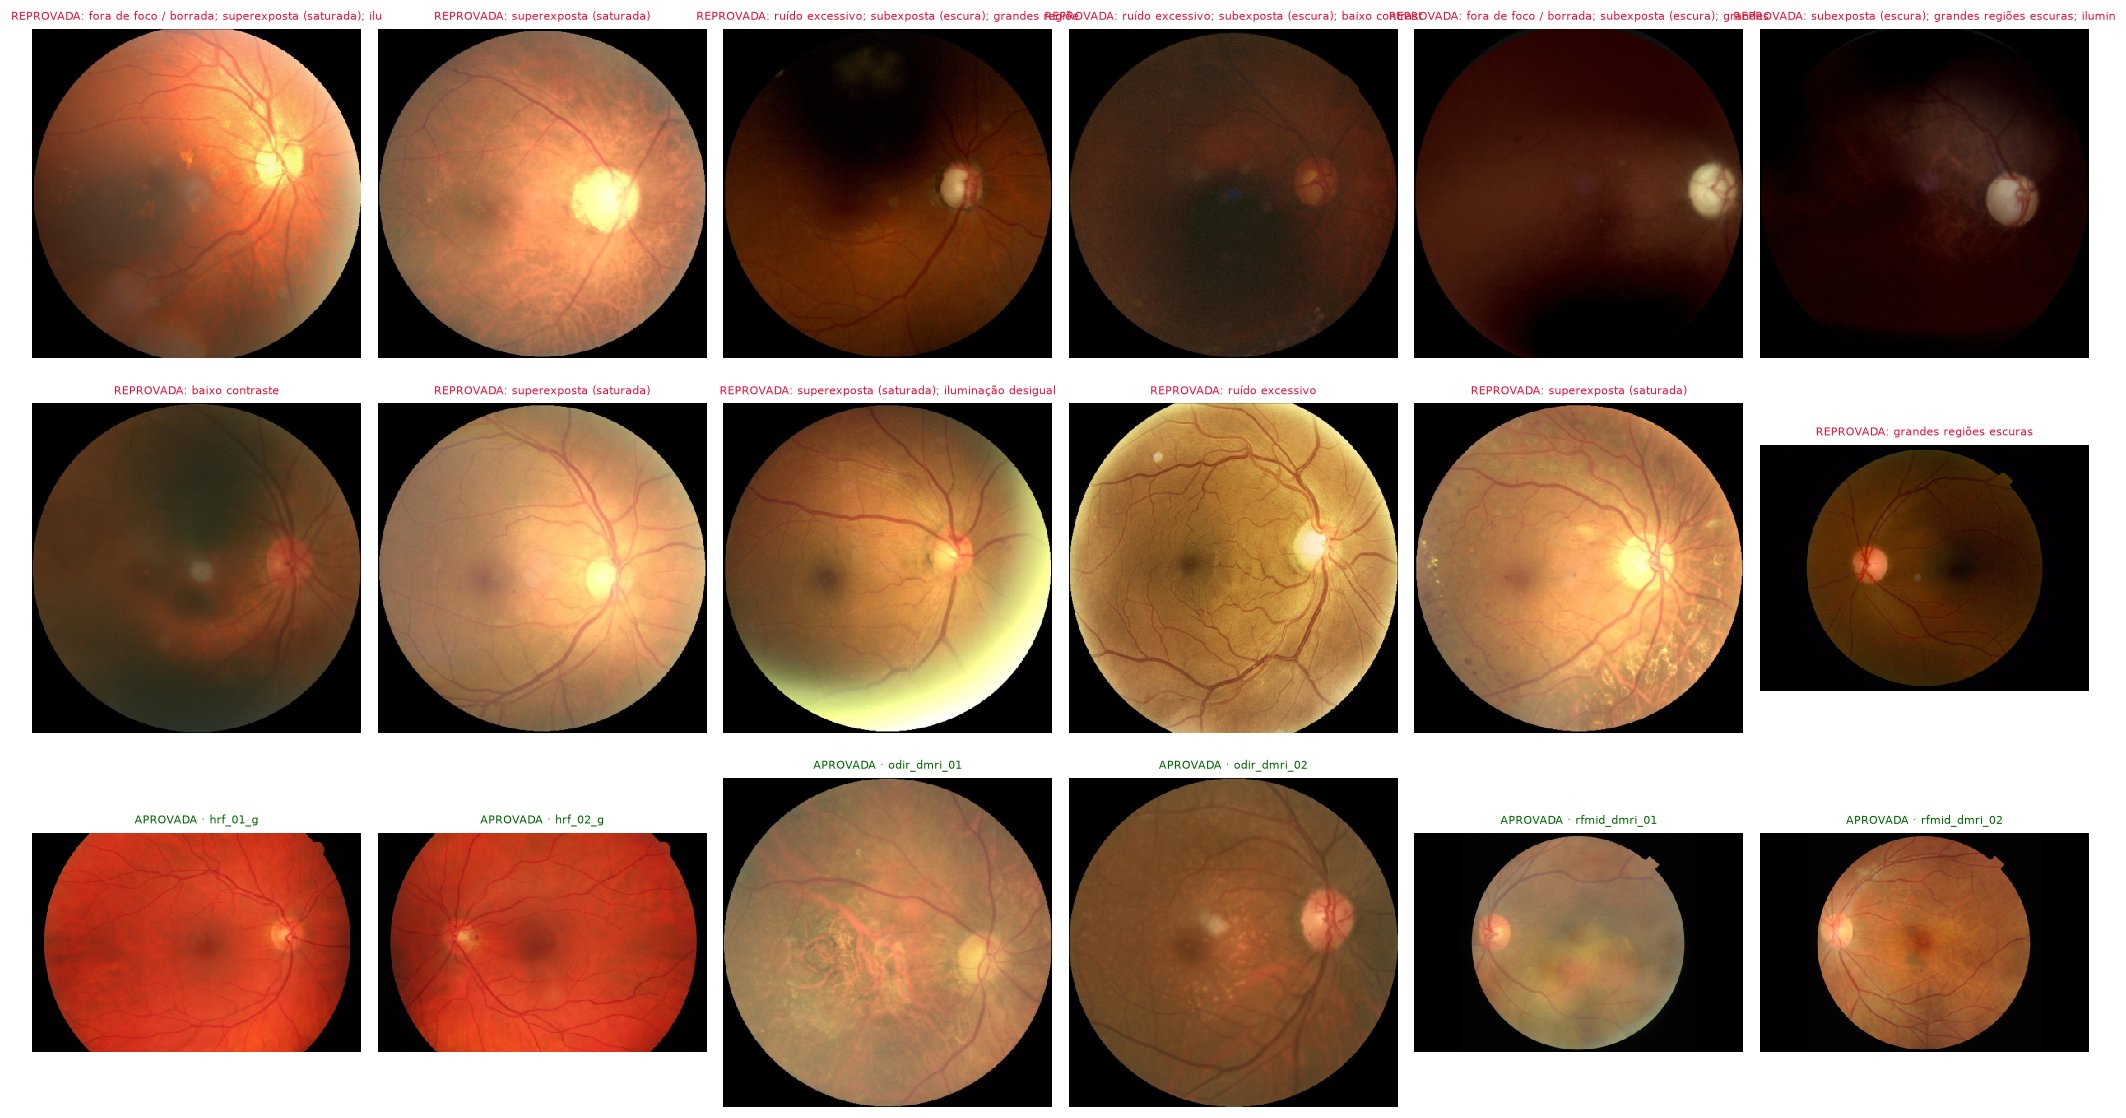

In [8]:
# Validação visual: as imagens que o avaliador reprovou realmente parecem ruins? E as aprovadas?
rep = real[~real.adequada].head(12)
apr = real[real.adequada].groupby("fonte").head(2).head(6)
fig, axs = plt.subplots(3, 6, figsize=(19, 10.5))
for ax in axs.ravel(): ax.axis("off")
for ax, (_, r) in zip(axs.ravel(), pd.concat([rep, apr]).iterrows()):
    im = dados.reduzir(dados.carregar_rgb(man.set_index("id").loc[r.id, "arquivo"]), 400)
    ax.imshow(im); ax.set_title(("REPROVADA: " + r.motivos[:52]) if not r.adequada else "APROVADA · " + r.id, fontsize=7, color="crimson" if not r.adequada else "darkgreen")
fig.tight_layout(); V.salvar_figura(fig, "05_reprovadas_vs_aprovadas"); plt.show()

Confira visualmente: as reprovadas concentram-se em capturas **escuras, saturadas, com sombras ou ruído**; as aprovadas são nítidas e bem iluminadas. Erros existem nos dois sentidos — é a etapa de **inspeção humana** que dá confiança ao avaliador.

### 4.2 Nas degradações sintéticas — taxa de detecção

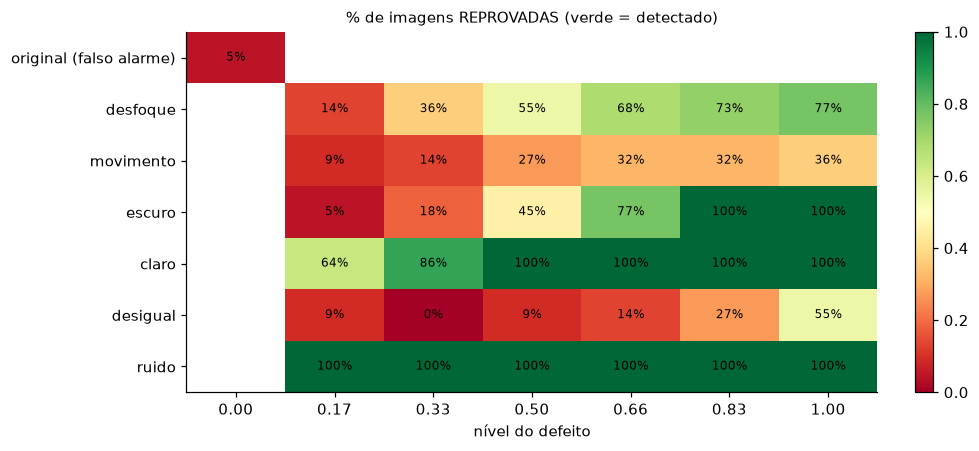

In [9]:
degr["adequada"], degr["motivos"] = julgar(degr)
deteccao = (1 - degr.groupby(["tipo", "nivel"]).adequada.mean()).unstack().reindex(["original", *degradacoes.TIPOS])
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(deteccao.values, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(deteccao.shape[1]), [f"{c:.2f}" for c in deteccao.columns]); ax.set_yticks(range(deteccao.shape[0]), [t if t != "original" else "original (falso alarme)" for t in deteccao.index])
for (i, j), v in np.ndenumerate(deteccao.values):
    if not np.isnan(v): ax.text(j, i, f"{100*v:.0f}%", ha="center", va="center", fontsize=8)
ax.set_xlabel("nível do defeito"); ax.set_title("% de imagens REPROVADAS (verde = detectado)"); fig.colorbar(im, fraction=0.03)
fig.tight_layout(); V.salvar_figura(fig, "05_taxa_de_deteccao"); plt.show()

* **Ruído:** detectado em 100 % das imagens em todos os níveis (até o mais fraco); **superexposição:** 100 % a partir do nível 0,5; **subexposição:** ≈ 77 % em 0,66 e 100 % a partir de 0,83.
* **Desfoque:** sobe de 14 % (nível 0,17) para ≈ 77 % (nível 1,0) — desfoques leves passam. **Movimento** (≤ ≈ 36 %) e **sombra suave** (só chega a ≈ 55 % no nível máximo) são os **pontos cegos** das regras atuais; melhorar isso é o exercício 3.
* Primeira linha: os **falsos alarmes** (originais reprovadas) — parte deles são capturas de fato ruins do ODIR.

## 5. Regras × classificador aprendido

Em vez de limiares manuais, um modelo pode aprender a decisão a partir das métricas. Treinamos regressão logística e floresta aleatória com rótulos **sintéticos** (degradação com nível ≥ 0,5 → "ruim"; original → "bom"),
com validação cruzada **por imagem** (`GroupKFold`): a mesma imagem-base nunca aparece no treino e no teste — senão o modelo "decora" a imagem.

In [10]:
feats = ["nitidez_rel", "tenengrad", "ruido", "brilho", "p_saturado", "p_escuro", "desigualdade", "contraste", "entropia"]
dd = degr[(degr.tipo == "original") | (degr.nivel >= 0.5)].reset_index(drop=True)
X, y, grupos = dd[feats].values, (dd.tipo != "original").astype(int).values, dd.id.values

modelos = {"regras (limiares padrão)": None,
           "regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
           "floresta aleatória": RandomForestClassifier(200, class_weight="balanced", random_state=0, min_samples_leaf=2)}
linhas = []
for nome, mdl in modelos.items():
    pred = (~dd.adequada.values).astype(int) if mdl is None else cross_val_predict(mdl, X, y, cv=GroupKFold(5), groups=grupos)
    linha = dict(modelo=nome, acurácia_balanceada=balanced_accuracy_score(y, pred), falso_alarme=((pred == 1) & (y == 0)).sum() / (y == 0).sum())
    for tipo in degradacoes.TIPOS:
        s = (dd.tipo == tipo).values; linha[f"detecta {tipo}"] = pred[s].mean()
    linhas.append(linha)
pd.DataFrame(linhas).set_index("modelo").round(2)

,acurácia_balanceada,falso_alarme,detecta desfoque,detecta movimento,detecta escuro,detecta claro,detecta desigual,detecta ruido
modelo,,,,,,,,
regras (limiares padrão),0.82,0.05,0.68,0.32,0.81,1.00,0.26,1.00
regressão logística,0.80,0.14,0.61,0.27,0.89,0.99,0.68,0.93
floresta aleatória,0.81,0.36,1.00,1.00,0.98,0.99,0.98,1.00


Leia a tabela com cuidado — **os modelos estão em pontos de operação diferentes**:

* As **regras** têm poucos falsos alarmes (≈ 5 %, por construção: limiares no percentil 5/95) e detectam bem ruído, superexposição e subexposição forte, mas falham em movimento e sombra.
* A **floresta aleatória** "detecta" quase tudo (inclusive movimento e sombra), porém ao custo de **muitos falsos alarmes** (≈ 36 %): com só 22 imagens "boas" contra centenas de "ruins", ela aprende a desconfiar de qualquer imagem diferente das 22. Não é uma comparação justa até igualar o nível de falsos alarmes.
* A **regressão logística** fica entre os dois e detecta melhor a sombra que as regras.

Ressalvas gerais: **(1)** os rótulos são *sintéticos* — defeitos reais (reflexos, pálpebra, catarata) podem não ser capturados; **(2)** a regra é **explicável** (diz *por que* reprovou), a floresta não; **(3)** qualquer um precisa ser recalibrado por câmera.
No dispositivo final, o ideal é rotular capturas **reais** (adequada/inadequada) na sessão do Lab Maker e treinar/validar com elas.

## 6. Limiares dependem da câmera: calibração no dispositivo

`Q.calibrar_limiares(metricas_de_capturas_boas)` deriva os limiares dos percentis das capturas **boas do próprio aparelho**. Simulamos três "dispositivos" (HRF, RFMiD, ODIR) e avaliamos cada conjunto de limiares em todas as fontes.

In [11]:
conjuntos = {"padrão": Q.LIMIARES_PADRAO, **{f"calibrado em {f}": Q.calibrar_limiares(real[real.fonte == f]) for f in ["HRF", "RFMiD", "ODIR"]}}
aprov = pd.DataFrame({nome: {f: julgar(real[real.fonte == f], lim)[0].mean() * 100 for f in ["HRF", "RFMiD", "ODIR"]} for nome, lim in conjuntos.items()}).T
aprov.columns = [f"% aprovadas · {c}" for c in aprov.columns]
det = {}
for nome, lim in conjuntos.items():
    fortes = degr[(degr.tipo != "original") & (degr.nivel >= 0.66)]
    det[nome] = {f: (1 - julgar(fortes[fortes.fonte == f], lim)[0].mean()) * 100 for f in ["HRF", "RFMiD", "ODIR"]}
det = pd.DataFrame(det).T; det.columns = [f"% defeitos fortes detectados · {c}" for c in det.columns]
pd.concat([aprov, det], axis=1).round(0)

,% aprovadas · HRF,% aprovadas · RFMiD,% aprovadas · ODIR,% defeitos fortes detectados · HRF,% defeitos fortes detectados · RFMiD,% defeitos fortes detectados · ODIR
padrão,100.0,96.0,74.0,60.0,71.0,81.0
calibrado em HRF,98.0,68.0,12.0,94.0,97.0,98.0
calibrado em RFMiD,100.0,93.0,48.0,63.0,71.0,83.0
calibrado em ODIR,100.0,100.0,93.0,52.0,56.0,62.0


Cada linha é um conjunto de limiares; cada coluna, uma câmera. O efeito é grande: os limiares **calibrados no HRF aprovam só ≈ 12 % das imagens do ODIR** (mesmo que muitas sejam boas), enquanto os **calibrados no ODIR detectam apenas ≈ 52 % dos defeitos fortes do HRF**.
Conclusão prática: **não reutilize limiares de uma base pública no retinógrafo** — capture 20–30 imagens boas (sessão do Lab Maker, notebook 01), calcule as métricas e chame `calibrar_limiares`.

## 7. Latência e estabilidade
O avaliador roda em cada captura (e idealmente no *preview* ao vivo, para orientar o operador). Medimos o tempo em função da resolução de entrada e a **estabilidade** da métrica de foco:

In [12]:
grande = dados.carregar_rgb(dados.selecionar("normal", "hrf").iloc[0].arquivo)
linhas = []
for larg in [3504, 2048, 1024, 512]:
    im = dados.reduzir(grande, larg)
    ts = []
    for _ in range(5):
        t0 = time.perf_counter(); m_ = Q.metricas_qualidade(im); ts.append((time.perf_counter() - t0) * 1e3)
    linhas.append(dict(largura=im.shape[1], ms_mediana=np.median(ts), nitidez_rel=m_["nitidez_rel"], brilho=m_["brilho"], ruido=m_["ruido"]))
lat = pd.DataFrame(linhas); lat["Δ nitidez_rel vs 1024"] = (lat.nitidez_rel / lat.loc[lat.largura == 1024, "nitidez_rel"].iloc[0] - 1) * 100
lat.round(3)

,largura,ms_mediana,nitidez_rel,brilho,ruido,Δ nitidez_rel vs 1024
0,3504,286.346,0.229,104.127,1.166,4.489
1,2048,141.855,0.227,104.137,1.095,3.464
2,1024,87.283,0.219,104.128,0.937,0.000
3,512,73.699,0.194,104.019,0.639,-11.654


Como as métricas são calculadas na versão padronizada 512×512, uma entrada de **1024 px** custa cerca de um terço do tempo de 3504 px e muda pouco os valores (≈ 4 % na nitidez).
Já com uma entrada de **512 px** a nitidez relativa cai ≈ 12 %: a padronização já não tem detalhe para reduzir. **Regra:** calibre e use os limiares **com a mesma resolução de entrada** (aqui, 1024 px).
No Raspberry Pi 5 recomenda-se avaliar um *preview* reduzido e só então capturar em resolução total (o tempo aqui é deste computador — **meça no Pi**).

## 8. Feedback ao operador
Motivos de reprovação viram instruções curtas (`Q.MENSAGENS_OPERADOR`):

[original] OK
[subexposta] Imagem escura: aumente a intensidade do LED ou o tempo de exposição. | Regiões escuras (pálpebra/cílios?): peça ao paciente para abrir mais o olho e realinhe. | Baixo contraste: verifique foco e opacidades (ex.: catarata) e repita a captura.
[superexposta] Muito ruído: aumente a iluminação em vez do ganho da câmera. | Imagem estourada: reduza a intensidade do LED ou o tempo de exposição.


[com ruído] Muito ruído: aumente a iluminação em vez do ganho da câmera.


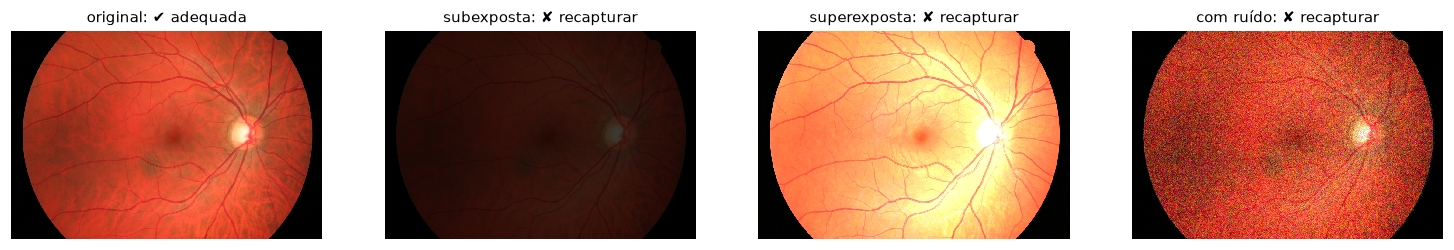

In [13]:
demo = [("original", dados.reduzir(grande, 1024)), ("subexposta", degradacoes.aplicar(dados.reduzir(grande, 1024), "escuro", 0.9)),
        ("superexposta", degradacoes.aplicar(dados.reduzir(grande, 1024), "claro", 0.7)), ("com ruído", degradacoes.aplicar(dados.reduzir(grande, 1024), "ruido", 0.8))]
fig, axs = plt.subplots(1, len(demo), figsize=(4.2 * len(demo), 4))
for ax, (t_, im) in zip(axs, demo):
    r_ = Q.avaliar_qualidade(im)
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{t_}: " + ("✔ adequada" if r_.adequada else "✘ recapturar"), fontsize=10)
    print(f"[{t_}]", "OK" if r_.adequada else " | ".join(Q.mensagens_para_operador(r_)))
plt.show()

## Exercícios propostos

1. **Limiares por defeito.** Escolha um defeito (ex.: desfoque) e desenhe a curva **ROC** do avaliador variando `nitidez_rel_min`. Qual limiar maximiza sensibilidade com ≤ 5 % de falsos alarmes? Está perto do padrão?
2. **Nova métrica: reflexos.** Reflexos brilhantes (córnea/lente) aparecem como manchas saturadas *dentro* do FOV. Implemente uma métrica (área do maior componente conexo com valor ≥ 250) e valide-a acrescentando reflexos sintéticos (círculos brancos suavizados).
3. **Detectar movimento.** O desfoque direcional deixa o gradiente **anisotrópico**. Calcule a razão entre energia do gradiente em *x* e em *y* (Sobel) e proponha uma regra. Ela detecta `movimento` sem aumentar os falsos alarmes?
4. **Calibração com dados reais.** Com as capturas do Lab Maker (≥ 20 boas, ≥ 10 defeituosas rotuladas por você), calcule as métricas, use `calibrar_limiares` nas boas e meça sensibilidade/especificidade nas defeituosas.
5. **Centralização.** Combine `localizar_disco_optico` (notebook 04) com o FOV para uma regra do tipo "disco/mácula dentro do terço central". Como ela se comporta em imagens de campo largo (HRF) e de campo estreito (RFMiD)?
6. **Robustez.** Aplique *duas* degradações ao mesmo tempo (ex.: desfoque + sombra). As métricas são aditivas? O avaliador ainda aponta ambos os motivos?